# Highway Network Testing

In [2]:
%load_ext autoreload
%autoreload 2
# normally Python imports a file only once, the notebook will keep using the old version until you restart the kernel.

import torch
import math
from main import (get_dataloaders, Net, HighwayLayer, PlainConv,
                  run_experiment, evaluate, DATA_DIR, DEVICE, SEED)

# Data prep
train_loader, val_loader, test_loader = get_dataloaders(DATA_DIR)
print("sizes:", len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))

images, labels = next(iter(train_loader))
print("batch:", tuple(images.shape), tuple(labels.shape))


# Testing the Highway layer
layer = HighwayLayer(channels=16)
x = torch.randn(8, 16, 32, 32)
y = layer(x)
print("in :", tuple(x.shape), "out:", tuple(y.shape))
print("gate mean at init:", torch.sigmoid(layer.gate(x)).mean().item())
print("params:", sum(p.numel() for p in layer.parameters()))
print()

sizes: 45000 5000 10000
batch: (128, 3, 32, 32) (128,)
in : (8, 16, 32, 32) out: (8, 16, 32, 32)
gate mean at init: 0.1319667100906372
params: 4640



### Random decisions

In [11]:
# Base line: 5,000 imgs, 10 classes, dataset is balanced = Random guessing accuracy = 1/10 = 0.1
print("baseline accuracy:", 1 / 10)

# The loss looks at the probability the model gives to the true class
# loss = −ln(p_true)
# p = (0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1)      # 10 classes, each 1/10
loss_base = - math.log(0.1)
print("baseline loss:", loss_base)
print()

baseline accuracy: 0.1
baseline loss: 2.3025850929940455



In [ ]:
print("=== Highway ===")
for lr in [0.3, 0.1, 0.03, 0.01, 0.003]:
    torch.manual_seed(SEED) # same starting weights for every lr
    model = Net(HighwayLayer, layers_per_stage=3, conv_init=False)
    print(f"\n--- lr = {lr} ---")
    history, best_acc = run_experiment(model, train_loader, val_loader, epochs=3, lr=lr, momentum=0.9, device=DEVICE)
    print("best val acc:", best_acc)
print()

print("=== PlainConv ===")
for lr in [0.3, 0.1, 0.03, 0.01, 0.003]:
    torch.manual_seed(SEED) # same starting weights for every lr
    model = Net(PlainConv, layers_per_stage=3, conv_init=False)
    print(f"\n--- lr = {lr} ---")
    history, best_acc = run_experiment(model, train_loader, val_loader, epochs=3, lr=lr, momentum=0.9, device=DEVICE)
    print("best val acc:", best_acc)

=== Highway ===

--- lr = 0.3 ---
epoch  1 | train loss 1.916 acc 0.266 | val loss 1.587 acc 0.376
epoch  2 | train loss 1.520 acc 0.439 | val loss 1.409 acc 0.477
epoch  3 | train loss 1.357 acc 0.510 | val loss 1.232 acc 0.551
best val acc: 0.5508

--- lr = 0.1 ---
epoch  1 | train loss 1.892 acc 0.277 | val loss 1.716 acc 0.333
epoch  2 | train loss 1.459 acc 0.461 | val loss 1.406 acc 0.494
epoch  3 | train loss 1.249 acc 0.549 | val loss 1.107 acc 0.611
best val acc: 0.611

--- lr = 0.03 ---
epoch  1 | train loss 2.050 acc 0.222 | val loss 1.752 acc 0.314
epoch  2 | train loss 1.683 acc 0.360 | val loss 1.571 acc 0.414
epoch  3 | train loss 1.485 acc 0.445 | val loss 1.433 acc 0.482
best val acc: 0.4824

--- lr = 0.01 ---
epoch  1 | train loss 2.196 acc 0.173 | val loss 2.029 acc 0.233
epoch  2 | train loss 1.932 acc 0.271 | val loss 1.752 acc 0.338
epoch  3 | train loss 1.724 acc 0.348 | val loss 1.667 acc 0.371
best val acc: 0.3706

--- lr = 0.003 ---
epoch  1 | train loss 2.298

Plain Conv doesn't learn at all, at any learning rate. Needs proper, better normalized initialization.


```py
# added in Net Class
for m in self.modules():
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
```

In [4]:
print("=== PlainConv ===")
for lr in [0.3, 0.1, 0.03, 0.01, 0.003]:
    torch.manual_seed(SEED) # same starting weights for every lr
    model = Net(PlainConv, layers_per_stage=3, conv_init=True)
    print(f"\n--- lr = {lr} ---")
    history, best_acc = run_experiment(model, train_loader, val_loader, epochs=6, lr=lr, momentum=0.9, device=DEVICE)
    print("best val acc:", best_acc)

=== PlainConv ===

--- lr = 0.3 ---
epoch  1 | train loss nan acc 0.100 | val loss nan acc 0.100
epoch  2 | train loss nan acc 0.100 | val loss nan acc 0.100
epoch  3 | train loss nan acc 0.100 | val loss nan acc 0.100
epoch  4 | train loss nan acc 0.100 | val loss nan acc 0.100
epoch  5 | train loss nan acc 0.100 | val loss nan acc 0.100
epoch  6 | train loss nan acc 0.100 | val loss nan acc 0.100
best val acc: 0.1

--- lr = 0.1 ---
epoch  1 | train loss 2.301 acc 0.110 | val loss 2.305 acc 0.100
epoch  2 | train loss 2.302 acc 0.104 | val loss 2.303 acc 0.100
epoch  3 | train loss 2.302 acc 0.104 | val loss 2.304 acc 0.100
epoch  4 | train loss 2.304 acc 0.097 | val loss 2.303 acc 0.100
epoch  5 | train loss 2.305 acc 0.100 | val loss 2.304 acc 0.100
epoch  6 | train loss 2.305 acc 0.098 | val loss 2.306 acc 0.100
best val acc: 0.1

--- lr = 0.03 ---
epoch  1 | train loss 2.097 acc 0.205 | val loss 1.859 acc 0.285
epoch  2 | train loss 1.752 acc 0.331 | val loss 1.653 acc 0.364
epoch

For `lr=0.3` and `lr=0.1` it was dead, but with lowering the learning rate we see it come alive.

In [5]:
print("=== Highway ===")
for lr in [0.3, 0.1, 0.03, 0.01, 0.003]:
    torch.manual_seed(SEED) # same starting weights for every lr
    model = Net(HighwayLayer, layers_per_stage=3, conv_init=True)
    print(f"\n--- lr = {lr} ---")
    history, best_acc = run_experiment(model, train_loader, val_loader, epochs=6, lr=lr, momentum=0.9, device=DEVICE)
    print("best val acc:", best_acc)
print()

=== Highway ===

--- lr = 0.3 ---
epoch  1 | train loss 1.845 acc 0.294 | val loss 1.531 acc 0.421
epoch  2 | train loss 1.490 acc 0.443 | val loss 1.422 acc 0.501
epoch  3 | train loss 1.351 acc 0.513 | val loss 1.282 acc 0.540
epoch  4 | train loss 1.234 acc 0.556 | val loss 1.105 acc 0.614
epoch  5 | train loss 1.172 acc 0.582 | val loss 1.131 acc 0.589
epoch  6 | train loss 1.128 acc 0.604 | val loss 1.041 acc 0.642
best val acc: 0.642

--- lr = 0.1 ---
epoch  1 | train loss 1.831 acc 0.301 | val loss 1.452 acc 0.454
epoch  2 | train loss 1.414 acc 0.477 | val loss 1.234 acc 0.546
epoch  3 | train loss 1.191 acc 0.572 | val loss 1.154 acc 0.604
epoch  4 | train loss 1.052 acc 0.627 | val loss 1.047 acc 0.638
epoch  5 | train loss 0.940 acc 0.666 | val loss 0.976 acc 0.660
epoch  6 | train loss 0.851 acc 0.700 | val loss 0.780 acc 0.725
best val acc: 0.7246

--- lr = 0.03 ---
epoch  1 | train loss 1.860 acc 0.294 | val loss 1.599 acc 0.368
epoch  2 | train loss 1.494 acc 0.443 | val

As we can see the best learning rate is:
- PlainConv `lr=0.01`
- Highway `lr=0.1`

## More layers, Deeper

Net has 3 stages. Each stage has 1 plain conv (to change the channels) plus N layers of chosen type (Highway or PlainConv):


```bash
depth = 3 stems + 3 × N
```
| layers_per_stage (N) | depth (conv layers) |
|---:|---:|
| 1  | 3 + 3 = 6   |
| 3  | 3 + 9 = 12  |
| 6  | 3 + 18 = 21 |
| 10 | 3 + 30 = 33 |



In [1]:
import json

configs = [("highway", HighwayLayer, 0.1),
           ("plain",   PlainConv,    0.01)]

results = {}
for name, layer_type, lr in configs:
    
    for lps in [1, 3, 6, 10]:
        torch.manual_seed(SEED)               # same start for every run
        depth = 3 + 3 * lps
        print(f"\n=== {name} | layers_per_stage={lps} (depth {depth}) | lr={lr} ===")

        model = Net(layer_type, layers_per_stage=lps, conv_init=True)
        history, best_acc = run_experiment(model, train_loader, val_loader,
                                           epochs=10, lr=lr, momentum=0.9, device=DEVICE)
        print("best val acc:", best_acc)

        results[f"{name}_{lps}"] = {"name": name, "lps": lps, "depth": depth, "lr": lr,
                                    "best_acc": best_acc, "history": history}

        
        with open("depth_results.json", "w") as f:
            json.dump(results, f, indent=2)     # save after EVERY run


NameError: name 'HighwayLayer' is not defined

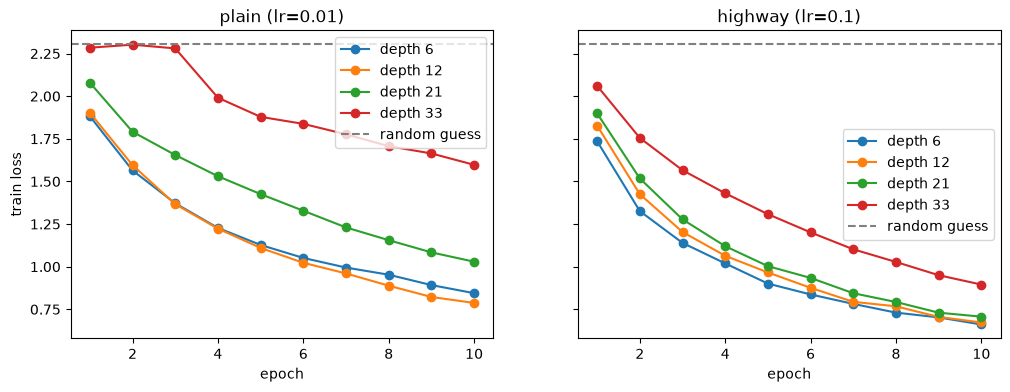

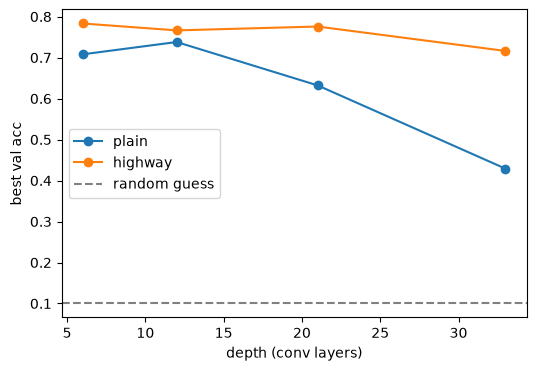

In [ ]:
import json
import matplotlib.pyplot as plt

with open("depth_results.json") as f:
    results = json.load(f)

# Plot 1: training loss vs epoch, one line per depth (like the paper's Fig 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ["plain", "highway"]):
    runs = [r for r in results.values() if r["name"] == name]
    for r in runs:
        epochs = range(1, len(r["history"]["train_loss"]) + 1)
        ax.plot(epochs, r["history"]["train_loss"], marker="o", label=f"depth {r['depth']}")
    ax.axhline(2.303, color="gray", linestyle="--", label="random guess")
    ax.set_title(f"{name} (lr={runs[0]['lr']})")
    ax.set_xlabel("epoch")
    ax.legend()

axes[0].set_ylabel("train loss")
plt.show()

# Plot 2: best val acc vs depth
plt.figure(figsize=(6, 4))
for name in ["plain", "highway"]:
    runs = sorted((r for r in results.values() if r["name"] == name), key=lambda r: r["depth"])
    plt.plot([r["depth"] for r in runs], [r["best_acc"] for r in runs], marker="o", label=name)
plt.axhline(0.1, color="gray", linestyle="--", label="random guess")
plt.xlabel("depth (conv layers)")
plt.ylabel("best val acc")
plt.legend()
plt.show()


Deep plain might do better at a smaller learning rate. Plain-33depth once at lr=0.003:

In [ ]:
print("=== PlainConv-33 ===")
for lr in [0.003]:
    torch.manual_seed(SEED) # same starting weights for every lr
    model = Net(PlainConv, layers_per_stage=10, conv_init=True)
    print(f"\n--- lr = {lr} ---")
    history, best_acc = run_experiment(model, train_loader, val_loader, epochs=10, lr=lr, momentum=0.9, device=DEVICE)
    print("best val acc:", best_acc)
print()

=== PlainConv-33 ===

--- lr = 0.003 ---
epoch  1 | train loss 2.228 acc 0.150 | val loss 2.086 acc 0.219
epoch  2 | train loss 1.947 acc 0.254 | val loss 1.887 acc 0.280
epoch  3 | train loss 1.808 acc 0.309 | val loss 1.717 acc 0.362
epoch  4 | train loss 1.708 acc 0.350 | val loss 1.674 acc 0.363
epoch  5 | train loss 1.600 acc 0.395 | val loss 1.587 acc 0.418
epoch  6 | train loss 1.520 acc 0.434 | val loss 1.373 acc 0.486
epoch  7 | train loss 1.435 acc 0.470 | val loss 1.393 acc 0.487
epoch  8 | train loss 1.346 acc 0.506 | val loss 1.231 acc 0.552
epoch  9 | train loss 1.296 acc 0.528 | val loss 1.225 acc 0.554
epoch 10 | train loss 1.236 acc 0.552 | val loss 1.229 acc 0.556
best val acc: 0.5562



plain needed re-tuning, highway didn't.

To train at 33 layers, the plain net needed a 3× smaller lr.

The highway net worked at depth 33 with the same lr it had at depth 12.

Highway nets don't need to be re-tuned as they get deeper.

In [3]:
import json, os

EPOCHS = 30
OUT = "depth_results_30ep.json"

# lr for each (type, layers_per_stage)
lrs = {
    ("highway", 1): 0.1,  ("highway", 3): 0.1,  ("highway", 6): 0.1,  ("highway", 10): 0.1,
    ("plain",   1): 0.01, ("plain",   3): 0.01, ("plain",   6): 0.003, ("plain",  10): 0.003,
}
layer_types = {"highway": HighwayLayer, "plain": PlainConv}

# load what's already done (resume after a crash)
results = {}
if os.path.exists(OUT):
    with open(OUT) as f:
        results = json.load(f)

for (name, lps), lr in lrs.items():
    key = f"{name}_{lps}"
    if key in results:
        print(f"skip {key} (already done)")
        continue

    torch.manual_seed(SEED)
    depth = 3 + 3 * lps
    print(f"\n=== {name} | depth {depth} | lr={lr} | {EPOCHS} epochs ===")

    model = Net(layer_types[name], layers_per_stage=lps, conv_init=True)
    try:
        history, best_acc = run_experiment(model, train_loader, val_loader,
                                           epochs=EPOCHS, lr=lr, momentum=0.9, device=DEVICE)
    except RuntimeError as e:          # nan guard from train_one_epoch
        print("diverged:", e)
        history, best_acc = None, 0.1

    print("best val acc:", best_acc)
    results[key] = {"name": name, "lps": lps, "depth": depth, "lr": lr,
                    "best_acc": best_acc, "history": history}
    with open(OUT, "w") as f:
        json.dump(results, f, indent=2)

    del model                          # free GPU memory before the next run
    torch.cuda.empty_cache()


=== highway | depth 6 | lr=0.1 | 30 epochs ===
epoch  1 | train loss 1.741 acc 0.338 | val loss 1.564 acc 0.421
epoch  2 | train loss 1.340 acc 0.511 | val loss 1.393 acc 0.517
epoch  3 | train loss 1.138 acc 0.594 | val loss 1.039 acc 0.633
epoch  4 | train loss 1.014 acc 0.638 | val loss 1.130 acc 0.596
epoch  5 | train loss 0.899 acc 0.684 | val loss 0.963 acc 0.669
epoch  6 | train loss 0.836 acc 0.711 | val loss 0.804 acc 0.718
epoch  7 | train loss 0.769 acc 0.733 | val loss 0.814 acc 0.732
epoch  8 | train loss 0.742 acc 0.742 | val loss 0.658 acc 0.775
epoch  9 | train loss 0.697 acc 0.759 | val loss 0.667 acc 0.773
epoch 10 | train loss 0.668 acc 0.768 | val loss 0.644 acc 0.772
epoch 11 | train loss 0.648 acc 0.775 | val loss 0.660 acc 0.770
epoch 12 | train loss 0.627 acc 0.782 | val loss 0.730 acc 0.752
epoch 13 | train loss 0.612 acc 0.790 | val loss 0.647 acc 0.778
epoch 14 | train loss 0.596 acc 0.795 | val loss 0.661 acc 0.774
epoch 15 | train loss 0.582 acc 0.800 | va

### Intermediate results (before lr re-tuning)
Shallow (6–12 layers): no difference, both ~84%.

Deeper: plain gets worse, highway doesn't (up to 21 layers).
- Highway stays flat from 6 to 21 layers (83.1 -> 84.3 -> 83.7%) with the same lr = 0.1.
- Plain drops: 84.9 -> 78.8 -> 74.1%, even with a smaller lr (0.003) for depth 21 and 33.

Depth 33: tie (highway 74.3% vs plain 74.1%) - but not a fair result for highway.
- Epoch-1 loss of highway-33 was 383,537: gradient explosion at lr = 0.1.
- Clipping prevented nan, but the net reset to random (loss 2.30 in epoch 2) and spent the rest recovering.
- Highway nets are not immune: at 33 layers, lr 0.1 is too aggressive in the first steps.

TODO: lr search for highway-33 (0.1 / 0.03 / 0.01) and plain-21 (0.01 / 0.003), 10 epochs each.


In [4]:
search = {
    ("highway", 10): [0.1, 0.03, 0.01],
    ("plain",   6):  [0.01, 0.003],
}

for (name, lps), lr_list in search.items():
    for lr in lr_list:
        torch.manual_seed(SEED)
        print(f"\n=== {name} | depth {3 + 3 * lps} | lr={lr} | 10 epochs ===")
        model = Net(layer_types[name], layers_per_stage=lps, conv_init=True)
        try:
            history, best_acc = run_experiment(model, train_loader, val_loader,
                                               epochs=10, lr=lr, momentum=0.9, device=DEVICE)
        except RuntimeError as e:
            print("diverged:", e)
            best_acc = 0.1
        print("best val acc:", best_acc)
        del model
        torch.cuda.empty_cache()



=== highway | depth 33 | lr=0.1 | 10 epochs ===
epoch  1 | train loss 234860.242 acc 0.108 | val loss 2.300 acc 0.103
epoch  2 | train loss 2.308 acc 0.101 | val loss 2.304 acc 0.100
epoch  3 | train loss 2.304 acc 0.101 | val loss 2.305 acc 0.100
epoch  4 | train loss 2.289 acc 0.110 | val loss 2.121 acc 0.176
epoch  5 | train loss 2.050 acc 0.202 | val loss 1.986 acc 0.185
epoch  6 | train loss 1.934 acc 0.237 | val loss 1.917 acc 0.258
epoch  7 | train loss 1.829 acc 0.285 | val loss 1.734 acc 0.326
epoch  8 | train loss 1.750 acc 0.325 | val loss 1.654 acc 0.371
epoch  9 | train loss 1.669 acc 0.370 | val loss 1.676 acc 0.390
epoch 10 | train loss 1.604 acc 0.399 | val loss 1.617 acc 0.407
best val acc: 0.4072

=== highway | depth 33 | lr=0.03 | 10 epochs ===
epoch  1 | train loss 2.076 acc 0.210 | val loss 1.908 acc 0.262
epoch  2 | train loss 1.728 acc 0.352 | val loss 1.506 acc 0.431
epoch  3 | train loss 1.521 acc 0.433 | val loss 1.431 acc 0.445
epoch  4 | train loss 1.375 ac

So this are optimal:
```py
("highway", 10): 0.03,
("plain",   6):  0.01,
```

In [6]:
import json, os

EPOCHS = 30
OUT = "depth_results_30ep.json"

# lr for each (type, layers_per_stage)
lrs = {
    ("highway", 1): 0.1,  ("highway", 3): 0.1,  ("highway", 6): 0.1,  ("highway", 10): 0.03,
    ("plain",   1): 0.01, ("plain",   3): 0.01, ("plain",   6): 0.01, ("plain",  10): 0.003,
}
layer_types = {"highway": HighwayLayer, "plain": PlainConv}

# load what's already done (resume after a crash)
results = {}
if os.path.exists(OUT):
    with open(OUT) as f:
        results = json.load(f)

for (name, lps), lr in lrs.items():
    key = f"{name}_{lps}"
    if key in results:
        print(f"skip {key} (already done)")
        continue

    torch.manual_seed(SEED)
    depth = 3 + 3 * lps
    print(f"\n=== {name} | depth {depth} | lr={lr} | {EPOCHS} epochs ===")

    model = Net(layer_types[name], layers_per_stage=lps, conv_init=True)
    try:
        history, best_acc = run_experiment(model, train_loader, val_loader,
                                           epochs=EPOCHS, lr=lr, momentum=0.9, device=DEVICE)
    except RuntimeError as e:          # nan guard from train_one_epoch
        print("diverged:", e)
        history, best_acc = None, 0.1

    print("best val acc:", best_acc)
    results[key] = {"name": name, "lps": lps, "depth": depth, "lr": lr,
                    "best_acc": best_acc, "history": history}
    with open(OUT, "w") as f:
        json.dump(results, f, indent=2)

    del model                          # free GPU memory before the next run
    torch.cuda.empty_cache()

skip highway_1 (already done)
skip highway_3 (already done)
skip highway_6 (already done)

=== highway | depth 33 | lr=0.03 | 30 epochs ===
epoch  1 | train loss 305210.201 acc 0.121 | val loss 2.103 acc 0.191
epoch  2 | train loss 2.005 acc 0.228 | val loss 1.813 acc 0.307
epoch  3 | train loss 1.781 acc 0.325 | val loss 1.703 acc 0.348
epoch  4 | train loss 1.660 acc 0.375 | val loss 1.695 acc 0.398
epoch  5 | train loss 1.568 acc 0.413 | val loss 1.504 acc 0.432
epoch  6 | train loss 1.503 acc 0.445 | val loss 1.378 acc 0.498
epoch  7 | train loss 1.405 acc 0.483 | val loss 1.309 acc 0.521
epoch  8 | train loss 1.279 acc 0.538 | val loss 1.292 acc 0.515
epoch  9 | train loss 1.173 acc 0.579 | val loss 1.079 acc 0.616
epoch 10 | train loss 1.082 acc 0.612 | val loss 0.981 acc 0.646
epoch 11 | train loss 0.997 acc 0.646 | val loss 0.900 acc 0.676
epoch 12 | train loss 0.952 acc 0.664 | val loss 0.896 acc 0.675
epoch 13 | train loss 0.877 acc 0.692 | val loss 0.748 acc 0.739
epoch 14 |

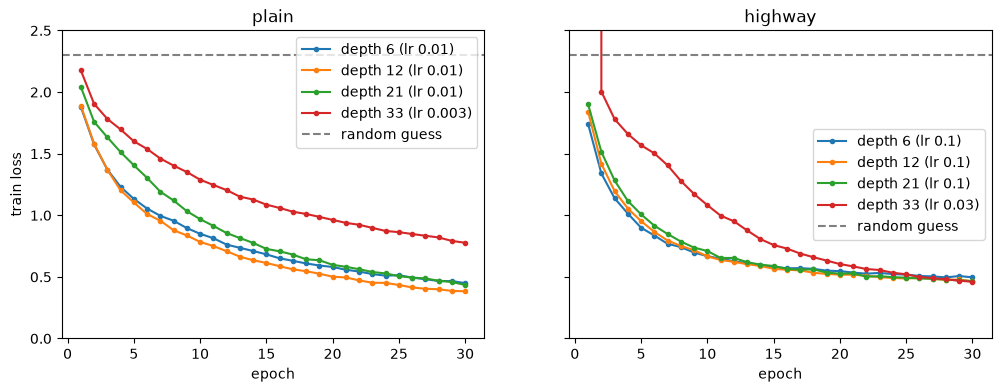

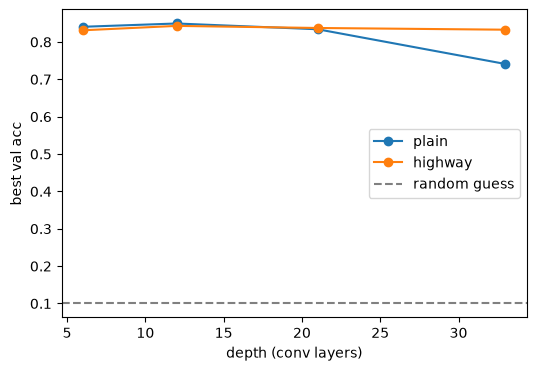

In [7]:
import json
import matplotlib.pyplot as plt

with open("depth_results_30ep.json") as f:
    results = json.load(f)

# Plot 1: training loss vs epoch, one line per depth (like the paper's Fig 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ["plain", "highway"]):
    runs = sorted((r for r in results.values() if r["name"] == name), key=lambda r: r["depth"])
    for r in runs:
        epochs = range(1, len(r["history"]["train_loss"]) + 1)
        ax.plot(epochs, r["history"]["train_loss"], marker="o", markersize=3,
                label=f"depth {r['depth']} (lr {r['lr']})")
    ax.axhline(2.303, color="gray", linestyle="--", label="random guess")
    ax.set_ylim(0, 2.5)                 # hide the huge epoch-1 spike of highway-33
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.legend()
axes[0].set_ylabel("train loss")
plt.show()

# Plot 2: best val acc vs depth
plt.figure(figsize=(6, 4))
for name in ["plain", "highway"]:
    runs = sorted((r for r in results.values() if r["name"] == name), key=lambda r: r["depth"])
    plt.plot([r["depth"] for r in runs], [r["best_acc"] for r in runs], marker="o", label=name)
plt.axhline(0.1, color="gray", linestyle="--", label="random guess")
plt.xlabel("depth (conv layers)")
plt.ylabel("best val acc")
plt.legend()
plt.show()
